# ADD transfer to entropic Set Partitioning

**Questions.** Does the assignment-selected GDF strategy improve final cost over Best Cost?
Do groups with larger exact maximum indicator ranks exhibit larger gains?

The primary presentation groups tasks by locality **w**. Each group has 135 tasks:
15 independent generated instances for each of nine combinations of m = 18, 19, 20
equalities and n = 13, 14, 15 (N = n² = 169, 196, 225 binary variables).
The two methods are paired on each task. There are 945 pairs / 1,890 solver runs.

Only the recovered directory `d962dbb8e6979cdd` is analyzed. Its 744 migrated pairs
are checked against their original files; the remaining 201 were completed after
removing redundant environment activation. Duplicate copies are not pooled.


In [1]:
from pathlib import Path
import csv, json, html
from IPython.display import display, HTML, Markdown, Image
root = Path.cwd()
if not (root / "Project.toml").exists():
    root = root.parent
out = root / "examples/add_locality_analysis"
def load(name):
    with (out / name).open(encoding="utf-8") as stream:
        return list(csv.DictReader(stream))
summary = load("gain_summary.csv")
tests = load("wilcoxon.csv")
meta = json.loads((out / "analysis_metadata.json").read_text(encoding="utf-8"))
def pct(value): return f"{float(value):.1f}%"
def pval(value):
    x=float(value)
    return f"{x:.2e}" if x < .001 else f"{x:.3f}"
def table(headers, rows):
    body="".join("<tr>"+"".join("<td>"+html.escape(str(v))+"</td>" for v in row)+"</tr>" for row in rows)
    display(HTML("<table><thead><tr>"+"".join("<th>"+html.escape(h)+"</th>" for h in headers)+"</tr></thead><tbody>"+body+"</tbody></table>"))
display(Markdown((out / "audit.md").read_text(encoding="utf-8")))


# Frozen ADD transfer audit

PASS: 945 distinct paired instances, 1890 complete solver runs; all 63 cells contain 15 instances. Only the recovered destination directory was analyzed.
744 migrated pairs match the original file hashes, solver statistics and diagnostics; 201 pairs are newly completed.
Validated input checksums, identical initial training fingerprints and per-iteration external-source fingerprints, configurations, 15 completed iterations, feasible final incumbents and recomputed objectives.
Stored exact ranks and cover counts were matched to the frozen manifest; no exact-indicator reconstruction or optimization was rerun.
Source signature: `d962dbb8e6979cdd`. Same iteration/sample settings, not equal wall time. Objective counters count unique cached evaluations. Timings exclude sampler construction and initial cost sorting and were collected concurrently; they are not isolated speed benchmarks.


## Experimental and statistical protocol

- GDF weight **0.4**, selected on assignment, versus Best Cost. No tuning on these results.
- The same 500 initial feasible draws; 15 outer iterations; 5,000 TT draws and
  5,000 fresh exact-uniform feasible draws per iteration. External draws are paired
  and their fingerprints match between methods at every iteration.
- Rebuild TT each iteration; one right-left sweep, learning rate 0.05, charge
  degeneracy one, table sampling backend, 5% elite retention, no worst-point retention.
- Objective: the saved 32-scenario entropic function, tau = 0.5 and scale sqrt(m).
  Each method has its own persistent objective cache. The incumbent includes all
  evaluated candidates, including the final external batch.
- The budget is equal iterations and requested samples, **not equal wall time or
  equal objective evaluations**. Concurrent timings are not isolated performance measurements.

For each pair, R = 100 (C_BestCost - C_ADD) / |C_BestCost|. Positive R favors ADD.
The exact maximum rank is that of the **full structural indicator** in the frozen
variable order, not the rank of the trained, sample-built TT.

As in the assignment reports, the A/B test is the one-sided paired Wilcoxon
signed-rank test on **raw final cost differences** (`HypothesisTests.SignedRankTest`,
right tail). Exact ties are excluded from ranking; all-zero groups receive p = 1.
Holm correction covers the seven locality tests; the 63 detailed-cell tests form a
separate exploratory family. The overall test is reported separately. This is not
a test specifically of mean percentage improvement; its location-shift interpretation
assumes symmetric paired differences. A paired sign test is included as a sensitivity check.

Mean-gain intervals are percentile paired bootstrap intervals (5,000 resamples),
stratified by the 63 design cells to preserve their representation. They are pointwise,
not simultaneous intervals. All displayed percentages are rounded to one decimal;
calculations use unrounded values. One optimizer seed per task limits inference about
repeat-run variability. These families were previously inspected in exploratory studies;
this is transfer of assignment-selected parameters, not a pristine preregistered test.


## Compact group comparison

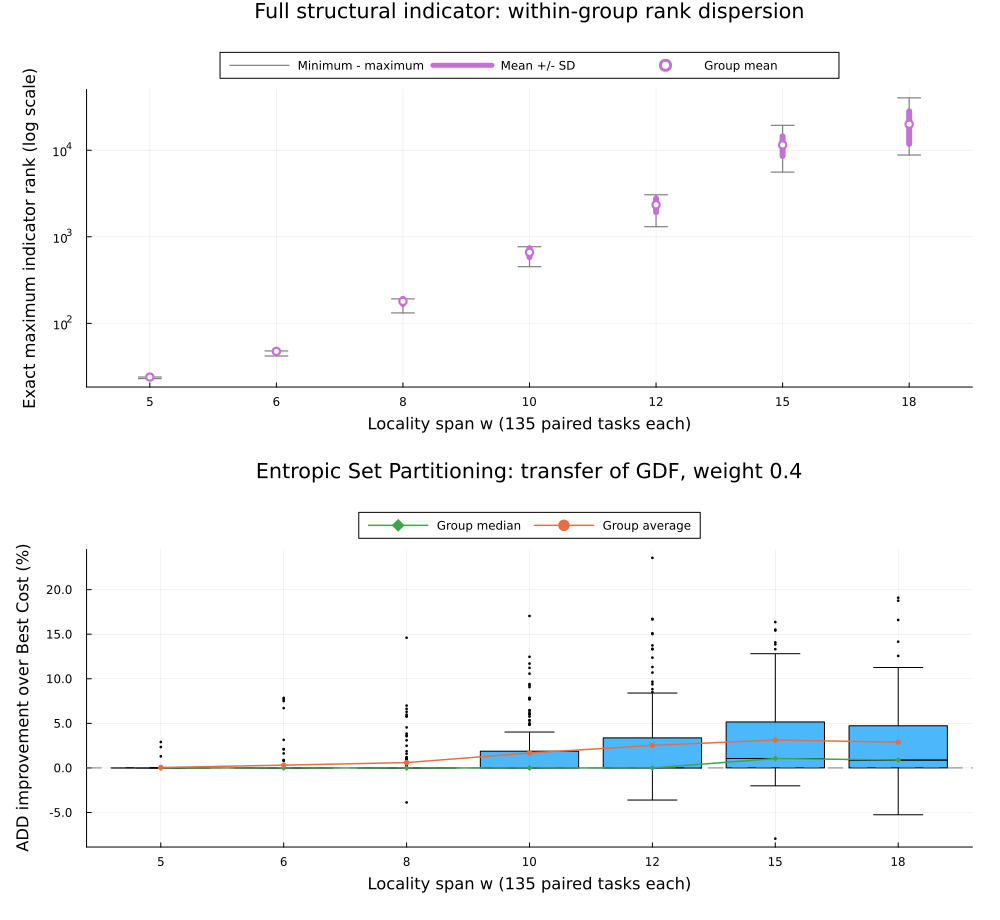

In [2]:
display(Image(filename=str(out / "transfer_by_locality.png")))


Both panels use the same seven locality groups. **Top:** the distribution of
exact maximum ranks over all 135 tasks in each group (logarithmic rank axis).
Thin gray intervals show the observed minimum and maximum; thick purple intervals
show the arithmetic mean +/- one sample standard deviation; hollow circles mark
the mean. These are dispersion intervals, not confidence intervals. Groups are
not connected by lines.
**Bottom:** paired relative improvements over those same tasks. Boxes show Q1–Q3,
the internal line is the median, whiskers extend to the most extreme observations
within 1.5 IQR, and points beyond are outliers. Green diamonds mark group medians;
orange circles mark group means in the bottom panel. Rank dispersion includes variation across all nine
(m,n) combinations, not merely the 15 repetitions of a single cell.


In [3]:
rank_rows = {r["w"]: r for r in load("rank_group_summary.csv")}
test_rows = {r["w"]: r for r in tests if r["level"] == "locality"}
table(["w", "Mean max rank ± SD", "Rank min–max", "ADD wins / ties / losses", "Mean gain", "95% CI", "Median gain", "Wilcoxon p (Holm 7)"], [
    [r["group"], f"{float(rank_rows[r['group']]['mean']):.0f} ± {float(rank_rows[r['group']]['sd']):.0f}",
     f"{int(float(rank_rows[r['group']]['minimum']))}–{int(float(rank_rows[r['group']]['maximum']))}",
     f"{r['wins']} / {r['ties']} / {r['losses']}", pct(r['mean_gain']),
     f"[{pct(r['mean_ci_low'])}, {pct(r['mean_ci_high'])}]", pct(r['median_gain']),pval(test_rows[r['group']]['p_holm'])]
    for r in summary[1:]])
r=summary[0]; t=next(r for r in tests if r['level']=='overall')
display(Markdown(f"**Overall:** mean gain **{pct(r['mean_gain'])}**, 95% CI [{pct(r['mean_ci_low'])}, {pct(r['mean_ci_high'])}]; median {pct(r['median_gain'])}. Wins/ties/losses: **{r['wins']}/{r['ties']}/{r['losses']}**. Paired Wilcoxon p = {pval(t['p'])}; sign-test p = {pval(meta['sign_test_p'])}."))


w,Mean max rank ± SD,Rank min–max,ADD wins / ties / losses,Mean gain,95% CI,Median gain,Wilcoxon p (Holm 7)
5,24 ± 0,23–24,3 / 132 / 0,0.0%,"[0.0%, 0.1%]",0.0%,0.125
6,47 ± 1,42–48,14 / 121 / 0,0.3%,"[0.1%, 0.5%]",0.0%,1.22e-04
8,180 ± 13,132–192,27 / 107 / 1,0.6%,"[0.3%, 0.9%]",0.0%,4.15e-06
10,660 ± 78,452–768,44 / 91 / 0,1.7%,"[1.2%, 2.2%]",0.0%,3.41e-13
12,2344 ± 418,1308–3052,63 / 69 / 3,2.5%,"[1.9%, 3.2%]",0.0%,1.07e-10
15,11513 ± 2948,5585–19388,75 / 56 / 4,3.1%,"[2.5%, 3.8%]",1.1%,1.55e-12
18,19962 ± 8136,8802–40232,79 / 52 / 4,2.9%,"[2.2%, 3.6%]",0.9%,2.52e-13


**Overall:** mean gain **1.6%**, 95% CI [1.4%, 1.8%]; median 0.0%. Wins/ties/losses: **305/628/12**. Paired Wilcoxon p = 2.01e-48; sign-test p = 6.79e-75.

## Interpretation

**ADD improves quality on this benchmark, but not on every task.** Most paired
results are exact ties. The advantage is concentrated in a subset of instances;
the overall zero median must be reported alongside the positive mean. Tiny numerical
differences do not explain the win counts: the counts are unchanged with a 1e-10
absolute tie tolerance. The denominator is bounded away from zero (see audit details below).

**The group-level pattern supports the proposed rank-related regime change.**
At w = 5, ranks are small, almost all outcomes coincide and the A/B test does not
establish an advantage. Mean improvements become larger across the intermediate
groups, reaching about 3% in the two largest-locality groups. The w = 18 mean is
slightly below w = 15: this is a broad increasing trend with a plateau, not strict
monotonicity. All groups from w = 6 onward have significant one-sided Wilcoxon
results after correction, although significance does not imply a large practical effect.

**Rank is associated with gain, not established as its isolated cause.** Locality
also changes the constraint structure, number of feasible solutions and objective
landscape on that space. Holding m and n fixed helps rule out size composition as
the sole explanation. It does not isolate rank from locality. The supplementary
analysis below makes this distinction explicit.


## Supplementary rank-association checks

In [4]:
display(Markdown(f"Across all individual tasks, Spearman rho = **{meta['pooled_spearman_rho']:.3f}** (descriptive two-sided p = {pval(meta['pooled_spearman_p'])}). The conclusion does not rely on treating seven group averages as 945 independent observations."))
models=load("rank_regressions.csv")
table(["Controls", "Gain slope per rank doubling (pp)", "95% HC3 interval (pp)", "Permutation p (Holm 3)", "Residual SD of log2 rank"], [
    [r['model'],f"{float(r['slope_pp_per_rank_doubling']):.1f}",
     f"[{float(r['ci_low']):.1f}, {float(r['ci_high']):.1f}]",pval(r['p_permutation_holm3']),f"{float(r['residual_log2_rank_sd']):.3f}"] for r in models])
associations=load("rank_by_size_constraints.csv")
table(["Equalities m", "Binary variables N", "Pairs", "Spearman rho", "p (Holm 9)"], [
    [r['m'],int(r['n'])**2,r['count'],f"{float(r['rho']):.3f}",pval(r['p_holm9'])] for r in associations])


Across all individual tasks, Spearman rho = **0.435** (descriptive two-sided p = 6.85e-45). The conclusion does not rely on treating seven group averages as 945 independent observations.

Controls,Gain slope per rank doubling (pp),95% HC3 interval (pp),Permutation p (Holm 3),Residual SD of log2 rank
Unadjusted,0.3,"[0.3, 0.4]",6.00e-04,3.474
Size and constraint count (9 cells),0.3,"[0.3, 0.4]",6.00e-04,3.471
"Size, constraint count and locality (63 cells)",0.9,"[-0.7, 2.5]",0.280,0.156


Equalities m,Binary variables N,Pairs,Spearman rho,p (Holm 9)
18,169,105,0.269,0.006
18,196,105,0.407,9.93e-05
18,225,105,0.403,1.00e-04
19,169,105,0.290,0.005
19,196,105,0.555,6.41e-09
19,225,105,0.449,1.10e-05
20,169,105,0.392,1.40e-04
20,196,105,0.388,1.40e-04
20,225,105,0.596,1.71e-10


The slope model is gain in percentage points versus log2(exact maximum rank).
HC3 intervals allow heteroskedasticity. The permutation test uses 5,000 permutations
of rank within the stated control strata (unrestricted, nine (m,n) cells, or 63
(w,m,n) cells). The smallest attainable raw p is 1/5,001. The linear slope is a
descriptive summary, not a mechanistic scaling law or an extrapolation beyond this grid.

The association is positive in each of the nine (m,n) groups and remains significant
after Holm correction. The adjusted slope is about **0.3 percentage points per rank
doubling**, but this reflects the broad cross-locality trend.

After additionally fixing locality, the within-cell slope is **not significant**
(permutation p approximately 0.28); residual rank variation is much smaller.
Thus these results support: *the assignment-selected ADD strategy transfers to
entropic Set Partitioning and is more useful in the higher-rank families studied*.
They do **not** establish a universal rank threshold, a causal effect of rank alone,
or a reliably positive rank effect among otherwise identical-locality tasks.


## Full 63-cell A/B table

In [5]:
cells=[r for r in tests if r['level']=='cell']
table(["w","m","N","Pairs","Mean max rank","Wins/ties/losses","Mean gain","Median gain","Wilcoxon p (Holm 63)"], [
    [r['w'],r['m'],int(r['n'])**2,r['N'],f"{float(r['mean_maxrank']):.0f}",
     f"{r['wins']}/{r['ties']}/{r['losses']}",pct(r['mean_relative']),pct(r['median_relative']),pval(r['p_holm'])] for r in cells])
display(Markdown(f"Minimum absolute Best Cost value: {meta['minimum_abs_baseline']:.6g}. Smallest nonzero absolute paired difference: {meta['minimum_nonzero_abs_difference']:.6g}. With tolerance 1e-10: {meta['tolerance_1e_10_wins']}/{meta['tolerance_1e_10_ties']}/{meta['tolerance_1e_10_losses']} wins/ties/losses."))


w,m,N,Pairs,Mean max rank,Wins/ties/losses,Mean gain,Median gain,Wilcoxon p (Holm 63)
5,18,169,15,24,0/15/0,0.0%,0.0%,1.000
5,18,196,15,24,0/15/0,0.0%,0.0%,1.000
5,18,225,15,24,1/14/0,0.1%,0.0%,1.000
5,19,169,15,24,0/15/0,0.0%,0.0%,1.000
5,19,196,15,24,1/14/0,0.2%,0.0%,1.000
5,19,225,15,24,1/14/0,0.2%,0.0%,1.000
5,20,169,15,24,0/15/0,0.0%,0.0%,1.000
5,20,196,15,24,0/15/0,0.0%,0.0%,1.000
5,20,225,15,24,0/15/0,0.0%,0.0%,1.000
6,18,169,15,48,0/15/0,0.0%,0.0%,1.000


Minimum absolute Best Cost value: 0.841908. Smallest nonzero absolute paired difference: 0.000154057. With tolerance 1e-10: 305/628/12 wins/ties/losses.

## Reproduction and files

Run from the repository root, in this order:

```bash
julia --startup-file=no --compiled-modules=existing --project=. --threads=1,0 scripts/report_ADD_locality_transfer.jl
python scripts/analyze_ADD_locality_transfer.py
julia --startup-file=no --compiled-modules=existing --project=. --threads=1,0 scripts/plot_ADD_locality_transfer.jl
python scripts/build_ADD_locality_notebook.py
```

Python analysis requires NumPy and SciPy; notebook generation requires nbformat,
nbclient and ipykernel. Julia uses the repository environment. No command runs an
optimizer. CSV exports, audit, statistical metadata and PDF/PNG figures are in
`examples/add_locality_analysis/`. The compact figure is `transfer_by_locality.pdf`.
